In [1]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load the real dataset
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url)

# Convert Month into a datetime index
df["Month"] = pd.to_datetime(df["Month"])
df = df.set_index("Month")

# Extract the passenger time series
series = df["Passengers"].astype(float)

# Display dataset
print(df.head())
print("\nDataset Shape:", df.shape)
print("\nDataset Description:")
print(df.describe())


            Passengers
Month                 
1949-01-01         112
1949-02-01         118
1949-03-01         132
1949-04-01         129
1949-05-01         121

Dataset Shape: (144, 1)

Dataset Description:
       Passengers
count  144.000000
mean   280.298611
std    119.966317
min    104.000000
25%    180.000000
50%    265.500000
75%    360.500000
max    622.000000


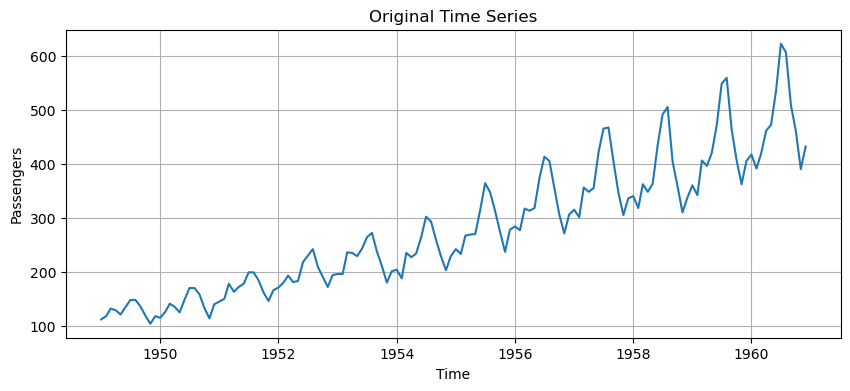

In [2]:


plt.figure(figsize=(10, 4))

plt.plot(series)

plt.title("Original Time Series")
plt.xlabel("Time")
plt.ylabel("Passengers")

plt.grid()
plt.show()

In [3]:
# Test stationarity using Augmented Dickey-Fuller test

adf_result = adfuller(series)

print("ADF statistic:", adf_result[0])
print("p-value:", adf_result[1])

ADF statistic: 0.8153688792060472
p-value: 0.991880243437641


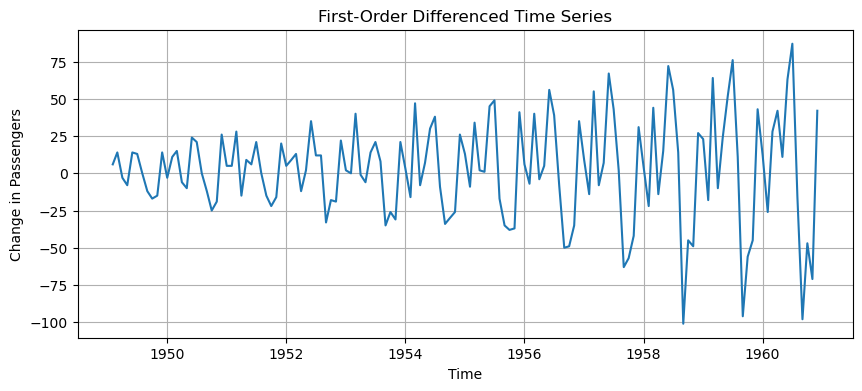

In [4]:
# First-order differencing
first_diff = series.diff().dropna()

# Plot the differenced series
plt.figure(figsize=(10, 4))
plt.plot(first_diff)
plt.title("First-Order Differenced Time Series")
plt.xlabel("Time")
plt.ylabel("Change in Passengers")
plt.grid()
plt.show()

In [5]:
# ADF test on first-order differenced data
adf_diff_result = adfuller(first_diff)

print("ADF Statistic:", adf_diff_result[0])
print("p-value:", adf_diff_result[1])

if adf_diff_result[1] <= 0.05:
    print("The differenced series is stationary.")
else:
    print("The differenced series is non-stationary.")

ADF Statistic: -2.8292668241699905
p-value: 0.05421329028382671
The differenced series is non-stationary.


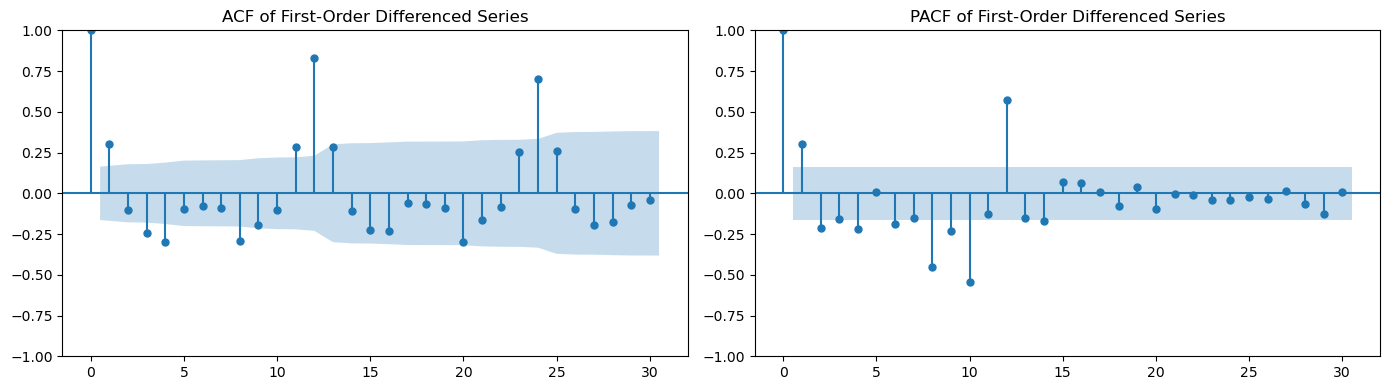

In [6]:
# ACF and PACF plots for differenced data
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(first_diff, lags=30, ax=axes[0])
axes[0].set_title("ACF of First-Order Differenced Series")

plot_pacf(first_diff, lags=30, ax=axes[1], method="ywm")
axes[1].set_title("PACF of First-Order Differenced Series")

plt.tight_layout()
plt.show()

In [7]:
# Split the dataset: 80% training and 20% testing
split_point = int(len(series) * 0.8)

train = series.iloc[:split_point]
test = series.iloc[split_point:]

print("Training data size:", len(train))
print("Testing data size:", len(test))
print("Training period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

Training data size: 115
Testing data size: 29
Training period: 1949-01-01 00:00:00 to 1958-07-01 00:00:00
Testing period: 1958-08-01 00:00:00 to 1960-12-01 00:00:00


In [10]:
# Fit ARIMA model
arima_model = ARIMA(train, order=(2, 1, 2))
arima_result = arima_model.fit()

print(arima_result.summary())

                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  115
Model:                 ARIMA(2, 1, 2)   Log Likelihood                -523.758
Date:                Mon, 02 Nov 2026   AIC                           1057.516
Time:                        10:01:12   BIC                           1071.197
Sample:                    01-01-1949   HQIC                          1063.069
                         - 07-01-1958                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3280      0.145      2.268      0.023       0.045       0.611
ar.L2          0.2521      0.165      1.528      0.126      -0.071       0.575
ma.L1         -0.0125      0.109     -0.114      0.9

In [9]:
# Explicitly assign monthly frequency
series = series.asfreq("MS")

# Recreate training and testing data
split_point = int(len(series) * 0.8)

train = series.iloc[:split_point]
test = series.iloc[split_point:]

print("Training shape:", train.shape)
print("Testing shape:", test.shape)

Training shape: (115,)
Testing shape: (29,)


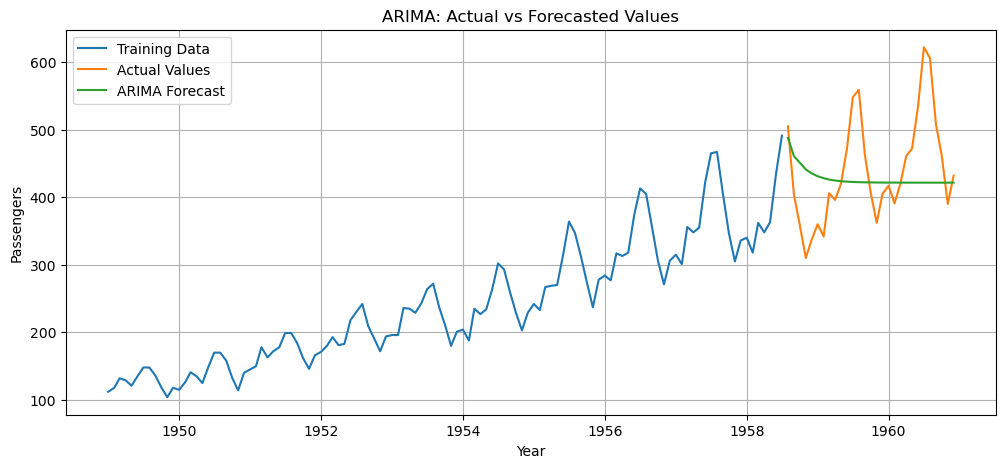

In [11]:
# Forecast for the testing period
arima_forecast = arima_result.forecast(steps=len(test))
arima_forecast.index = test.index

# Plot actual vs predicted values
plt.figure(figsize=(12, 5))
plt.plot(train.index, train, label="Training Data")
plt.plot(test.index, test, label="Actual Values")
plt.plot(test.index, arima_forecast, label="ARIMA Forecast")

plt.title("ARIMA: Actual vs Forecasted Values")
plt.xlabel("Year")
plt.ylabel("Passengers")
plt.legend()
plt.grid()
plt.show()

In [12]:
mae = mean_absolute_error(test, arima_forecast)
rmse = np.sqrt(mean_squared_error(test, arima_forecast))

print("Mean Absolute Error (MAE):", mae)
print("Root Mean Squared Error (RMSE):", rmse)

Mean Absolute Error (MAE): 63.54531127690957
Root Mean Squared Error (RMSE): 82.51301133837681


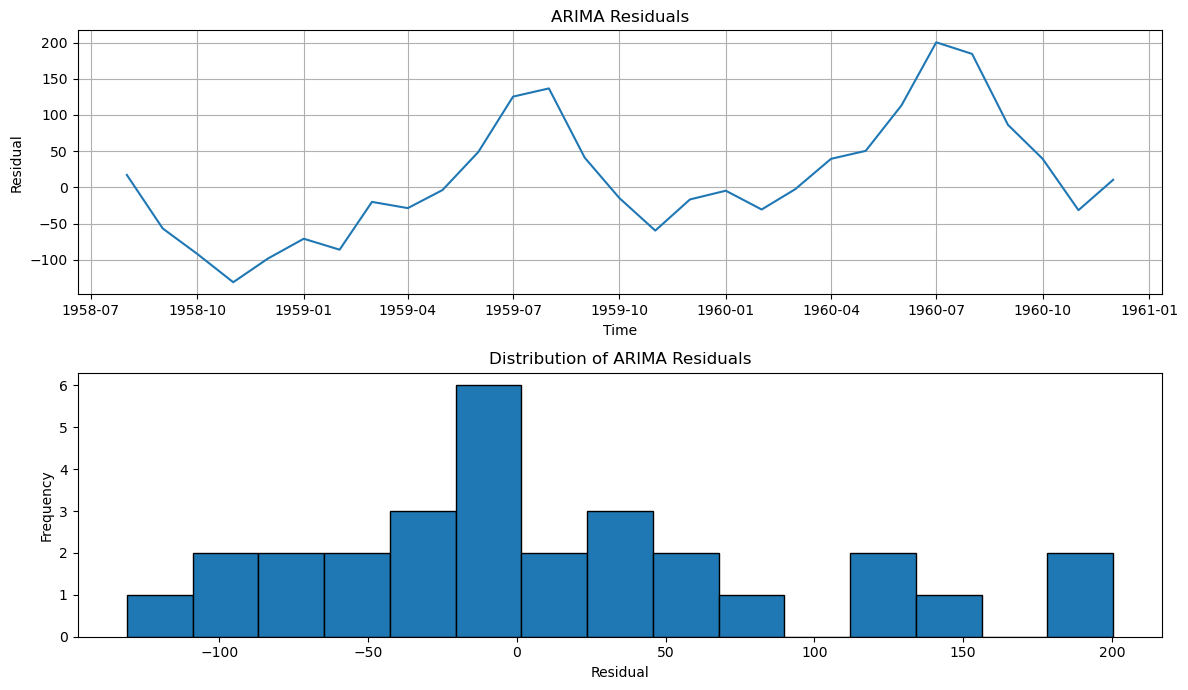

In [13]:
# Calculate residuals
residuals = test - arima_forecast

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

axes[0].plot(residuals)
axes[0].set_title("ARIMA Residuals")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Residual")
axes[0].grid()

axes[1].hist(residuals, bins=15, edgecolor="black")
axes[1].set_title("Distribution of ARIMA Residuals")
axes[1].set_xlabel("Residual")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

<Figure size 1000x400 with 0 Axes>

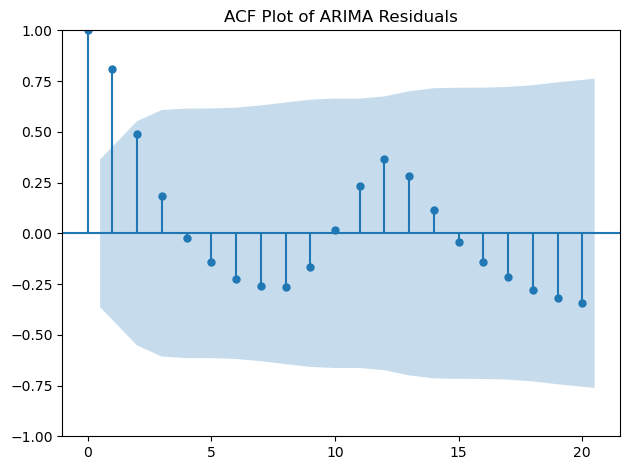

In [14]:
plt.figure(figsize=(10, 4))
plot_acf(residuals.dropna(), lags=20)
plt.title("ACF Plot of ARIMA Residuals")
plt.tight_layout()
plt.show()

In [15]:
# Compare different ARIMA configurations
orders = [(1, 1, 1), (2, 1, 1), (1, 1, 2), (2, 1, 2)]

arima_comparison = []

for order in orders:
    try:
        model = ARIMA(train, order=order)
        result = model.fit()
        forecast = result.forecast(steps=len(test))
        forecast.index = test.index

        mae_value = mean_absolute_error(test, forecast)
        rmse_value = np.sqrt(mean_squared_error(test, forecast))

        arima_comparison.append({
            "ARIMA Order": str(order),
            "AIC": result.aic,
            "MAE": mae_value,
            "RMSE": rmse_value
        })

    except Exception as e:
        print("Model failed for", order, ":", e)

arima_comparison_df = pd.DataFrame(arima_comparison)
display(arima_comparison_df.sort_values("RMSE"))

,ARIMA Order,AIC,MAE,RMSE
3,"(2, 1, 2)",1057.516178,63.545311,82.513011
1,"(2, 1, 1)",1058.647616,60.528996,82.621097
2,"(1, 1, 2)",1057.327535,62.063473,82.635764
0,"(1, 1, 1)",1058.245574,85.254156,97.499620


In [18]:
d_comparison = []

for d_value in [0, 1]:
    try:
        model = ARIMA(train, order=(2, d_value, 2))
        result = model.fit()
        forecast = result.forecast(steps=len(test))
        forecast.index = test.index

        d_comparison.append({
            "Differencing Order (d)": d_value,
            "AIC": result.aic,
            "MAE": mean_absolute_error(test, forecast),
            "RMSE": np.sqrt(mean_squared_error(test, forecast))
        })

    except Exception as e:
        print("Model failed for d =", d_value, ":", e)

display(pd.DataFrame(d_comparison))

,Differencing Order (d),AIC,MAE,RMSE
0,0,1074.541308,92.256516,114.904025
1,1,1057.516178,63.545311,82.513011


In [17]:
import warnings
warnings.filterwarnings("ignore")

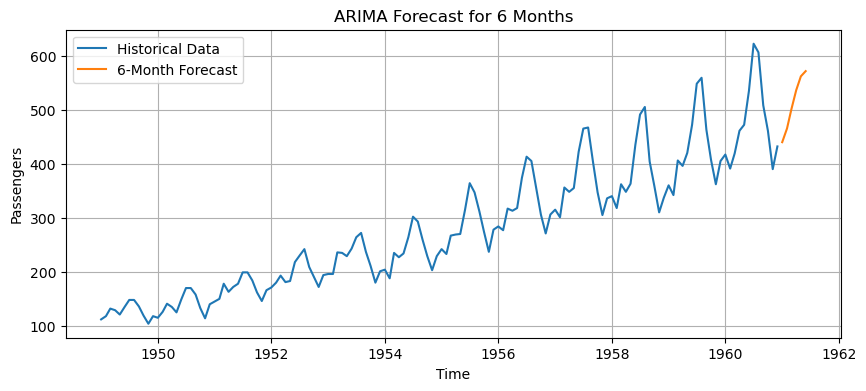


Forecast for next 6 months:
1961-01-01    439.854924
1961-02-01    465.296653
1961-03-01    500.666130
1961-04-01    535.971345
1961-05-01    561.688812
1961-06-01    571.312135
Freq: MS, Name: predicted_mean, dtype: float64


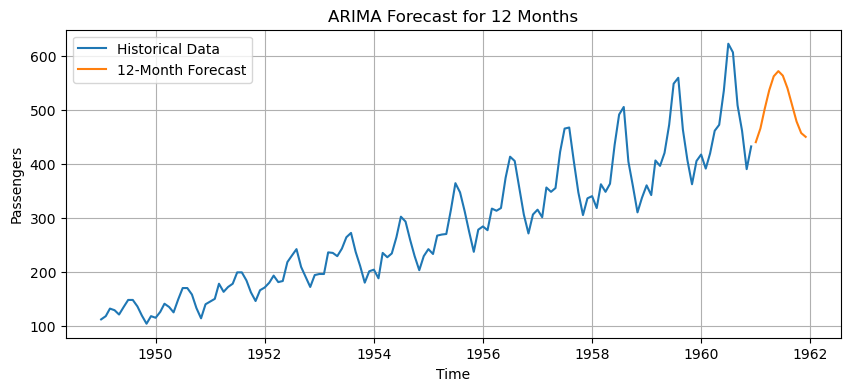


Forecast for next 12 months:
1961-01-01    439.854924
1961-02-01    465.296653
1961-03-01    500.666130
1961-04-01    535.971345
1961-05-01    561.688812
1961-06-01    571.312135
1961-07-01    562.971387
1961-08-01    539.728310
1961-09-01    508.527484
1961-10-01    478.147140
1961-11-01    456.747740
1961-12-01    449.697940
Freq: MS, Name: predicted_mean, dtype: float64


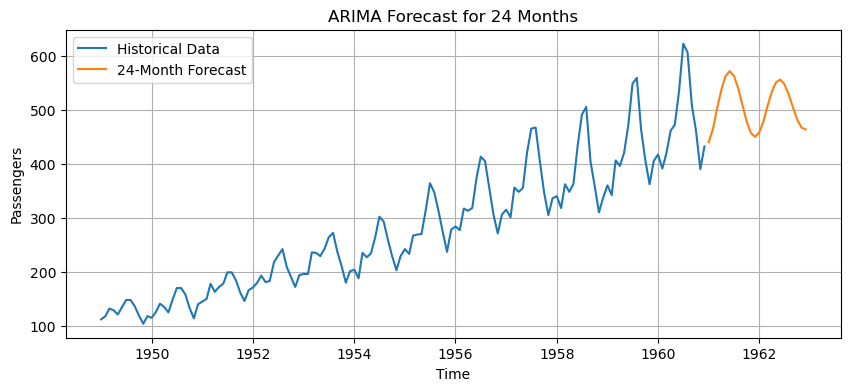


Forecast for next 24 months:
1961-01-01    439.854924
1961-02-01    465.296653
1961-03-01    500.666130
1961-04-01    535.971345
1961-05-01    561.688812
1961-06-01    571.312135
1961-07-01    562.971387
1961-08-01    539.728310
1961-09-01    508.527484
1961-10-01    478.147140
1961-11-01    456.747740
1961-12-01    449.697940
1962-01-01    458.252029
1962-02-01    479.397272
1962-03-01    506.859509
1962-04-01    532.943377
1962-05-01    550.672920
1962-06-01    555.641425
1962-07-01    547.084464
1962-08-01    527.921698
1962-09-01    503.802708
1962-10-01    481.459304
1962-11-01    466.840219
1962-12-01    463.541322
Freq: MS, Name: predicted_mean, dtype: float64


In [19]:
# Fit ARIMA on the complete dataset
full_arima_model = ARIMA(series, order=(2, 1, 2))
full_arima_result = full_arima_model.fit()

for horizon in [6, 12, 24]:
    future_forecast = full_arima_result.forecast(steps=horizon)

    plt.figure(figsize=(10, 4))
    plt.plot(series, label="Historical Data")
    plt.plot(future_forecast, label=f"{horizon}-Month Forecast")

    plt.title(f"ARIMA Forecast for {horizon} Months")
    plt.xlabel("Time")
    plt.ylabel("Passengers")
    plt.legend()
    plt.grid()
    plt.show()

    print(f"\nForecast for next {horizon} months:")
    print(future_forecast)

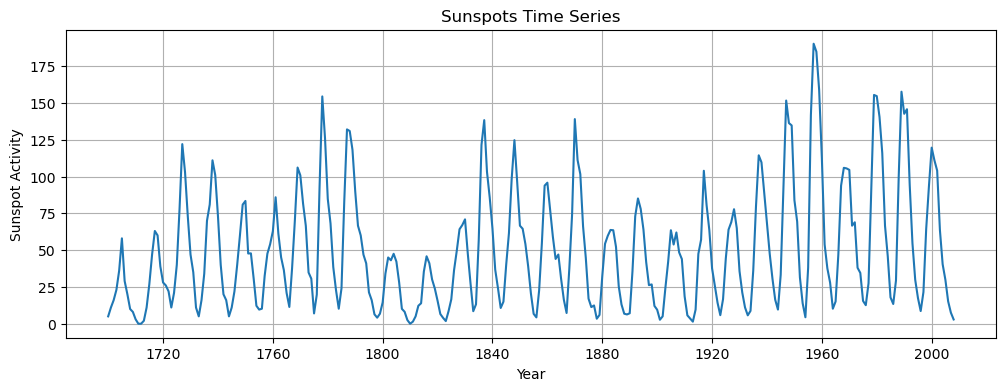

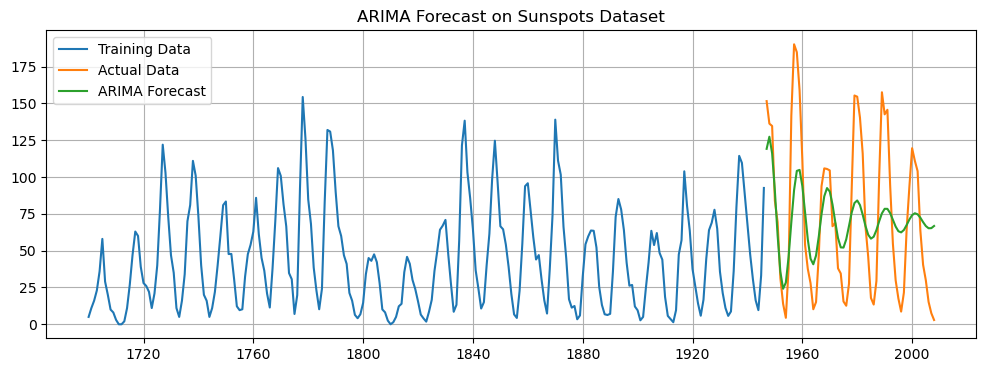

Sunspots MAE: 33.16126171209509
Sunspots RMSE: 40.22783912130266


In [20]:
from statsmodels.datasets import sunspots

# Load Sunspots dataset
sunspot_data = sunspots.load_pandas().data
sunspot_series = sunspot_data["SUNACTIVITY"].astype(float)

sunspot_series.index = pd.to_datetime(
    sunspot_data["YEAR"].astype(int).astype(str),
    format="%Y"
)

# Plot original dataset
plt.figure(figsize=(12, 4))
plt.plot(sunspot_series)
plt.title("Sunspots Time Series")
plt.xlabel("Year")
plt.ylabel("Sunspot Activity")
plt.grid()
plt.show()

# Split data
sunspot_split = int(len(sunspot_series) * 0.8)
sunspot_train = sunspot_series.iloc[:sunspot_split]
sunspot_test = sunspot_series.iloc[sunspot_split:]

# Fit ARIMA
sunspot_model = ARIMA(sunspot_train, order=(2, 1, 2))
sunspot_result = sunspot_model.fit()

# Forecast
sunspot_forecast = sunspot_result.forecast(steps=len(sunspot_test))
sunspot_forecast.index = sunspot_test.index

# Plot actual vs forecast
plt.figure(figsize=(12, 4))
plt.plot(sunspot_train, label="Training Data")
plt.plot(sunspot_test, label="Actual Data")
plt.plot(sunspot_forecast, label="ARIMA Forecast")
plt.title("ARIMA Forecast on Sunspots Dataset")
plt.legend()
plt.grid()
plt.show()

# Evaluation
print("Sunspots MAE:", mean_absolute_error(sunspot_test, sunspot_forecast))
print("Sunspots RMSE:", np.sqrt(mean_squared_error(sunspot_test, sunspot_forecast)))

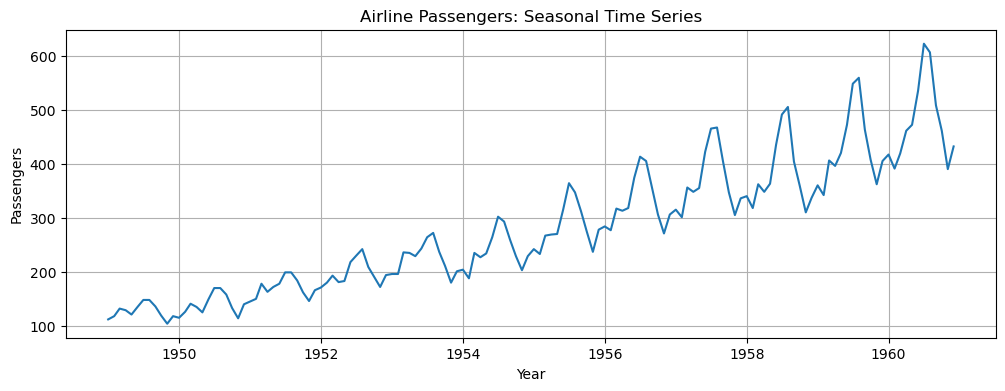

In [21]:
plt.figure(figsize=(12, 4))
plt.plot(series)
plt.title("Airline Passengers: Seasonal Time Series")
plt.xlabel("Year")
plt.ylabel("Passengers")
plt.grid()
plt.show()

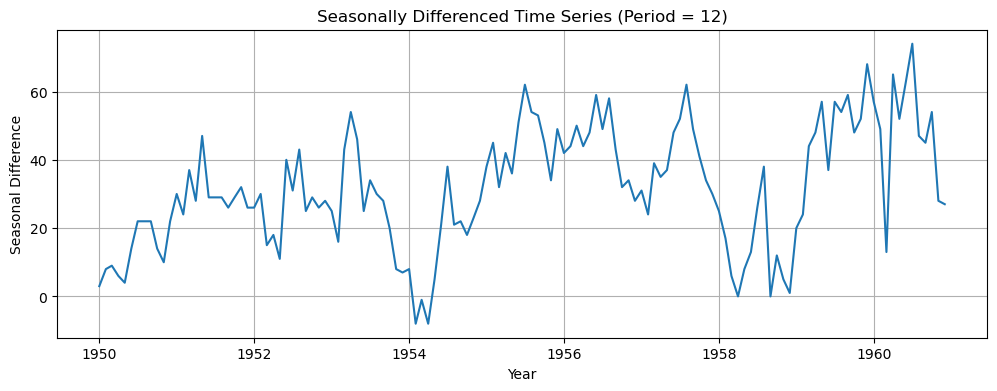

In [22]:
# Seasonal differencing with period 12
seasonal_diff = series.diff(12).dropna()

plt.figure(figsize=(12, 4))
plt.plot(seasonal_diff)
plt.title("Seasonally Differenced Time Series (Period = 12)")
plt.xlabel("Year")
plt.ylabel("Seasonal Difference")
plt.grid()
plt.show()

In [23]:
seasonal_adf = adfuller(seasonal_diff)

print("ADF Statistic:", seasonal_adf[0])
print("p-value:", seasonal_adf[1])

if seasonal_adf[1] <= 0.05:
    print("The seasonally differenced series is stationary.")
else:
    print("The seasonally differenced series is non-stationary.")

ADF Statistic: -3.3830207264924814
p-value: 0.011551493085514952
The seasonally differenced series is stationary.


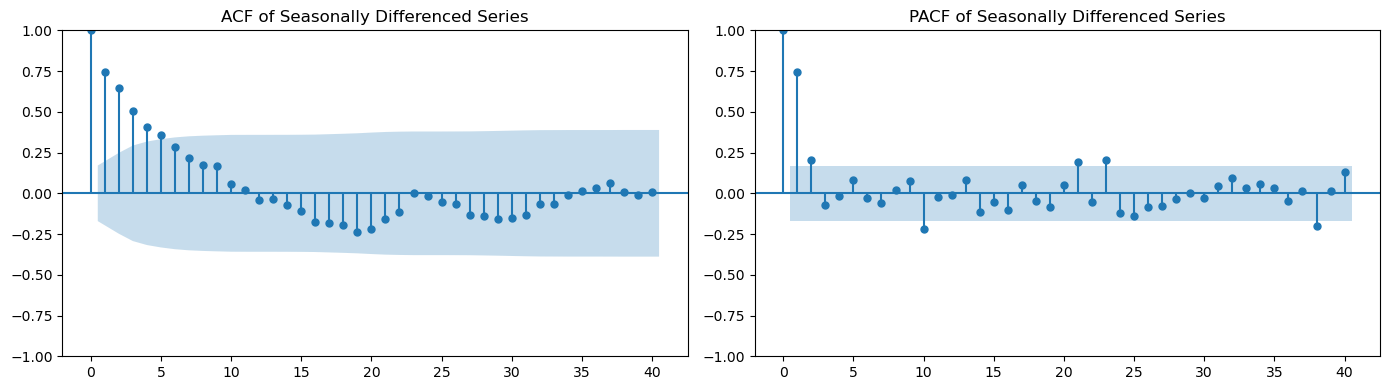

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(seasonal_diff, lags=40, ax=axes[0])
axes[0].set_title("ACF of Seasonally Differenced Series")

plot_pacf(seasonal_diff, lags=40, ax=axes[1], method="ywm")
axes[1].set_title("PACF of Seasonally Differenced Series")

plt.tight_layout()
plt.show()

In [25]:
sarima_split = int(len(series) * 0.8)

sarima_train = series.iloc[:sarima_split]
sarima_test = series.iloc[sarima_split:]

print("Training data size:", len(sarima_train))
print("Testing data size:", len(sarima_test))

Training data size: 115
Testing data size: 29


In [26]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima_model = SARIMAX(
    sarima_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_result = sarima_model.fit(disp=False)

print(sarima_result.summary())

                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  115
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -323.801
Date:                            Mon, 02 Nov 2026   AIC                            657.601
Time:                                    10:05:57   BIC                            669.988
Sample:                                01-01-1949   HQIC                           662.592
                                     - 07-01-1958                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.8224      0.184     -4.461      0.000      -1.184      -0.461
ma.L1          0.7176      0.224   

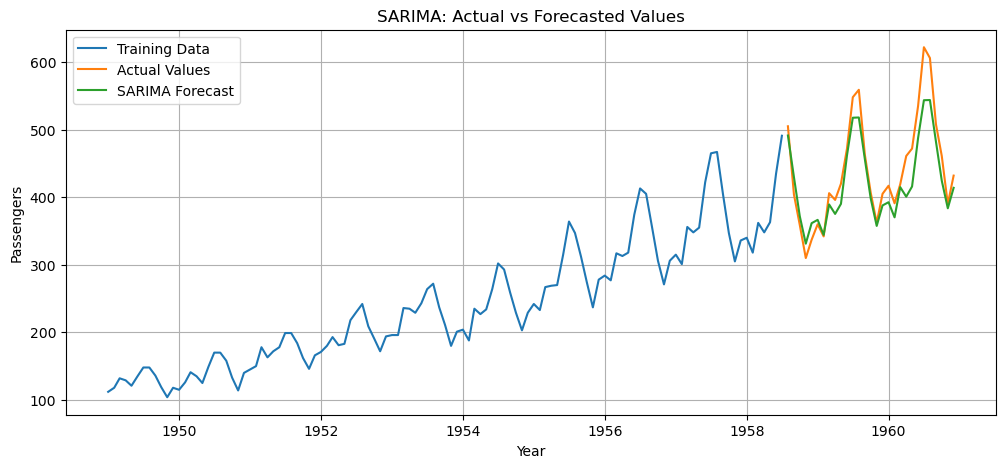

In [27]:
sarima_forecast = sarima_result.forecast(steps=len(sarima_test))
sarima_forecast.index = sarima_test.index

plt.figure(figsize=(12, 5))
plt.plot(sarima_train, label="Training Data")
plt.plot(sarima_test, label="Actual Values")
plt.plot(sarima_forecast, label="SARIMA Forecast")

plt.title("SARIMA: Actual vs Forecasted Values")
plt.xlabel("Year")
plt.ylabel("Passengers")
plt.legend()
plt.grid()
plt.show()

In [28]:
sarima_mae = mean_absolute_error(sarima_test, sarima_forecast)
sarima_rmse = np.sqrt(mean_squared_error(sarima_test, sarima_forecast))

print("SARIMA MAE:", sarima_mae)
print("SARIMA RMSE:", sarima_rmse)

SARIMA MAE: 25.2680456878996
SARIMA RMSE: 31.787297490441524


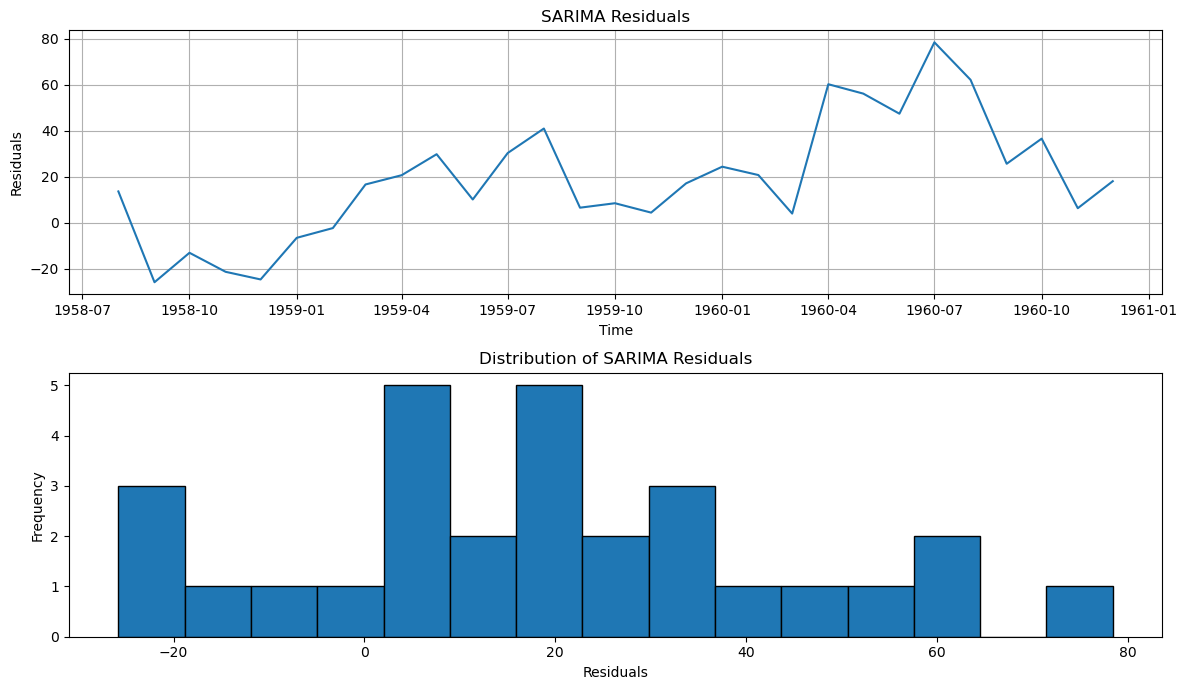

In [29]:
sarima_residuals = sarima_test - sarima_forecast

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

axes[0].plot(sarima_residuals)
axes[0].set_title("SARIMA Residuals")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Residuals")
axes[0].grid()

axes[1].hist(sarima_residuals, bins=15, edgecolor="black")
axes[1].set_title("Distribution of SARIMA Residuals")
axes[1].set_xlabel("Residuals")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

<Figure size 1000x400 with 0 Axes>

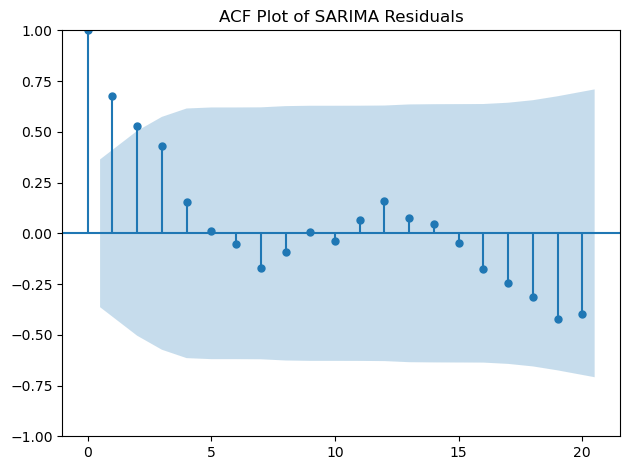

In [30]:
plt.figure(figsize=(10, 4))
plot_acf(sarima_residuals.dropna(), lags=20)
plt.title("ACF Plot of SARIMA Residuals")
plt.tight_layout()
plt.show()

In [31]:
sarima_orders = [
    ((1, 1, 1), (1, 1, 1, 12)),
    ((2, 1, 1), (1, 1, 1, 12)),
    ((1, 1, 2), (1, 1, 1, 12))
]

sarima_comparison = []

for order, seasonal_order in sarima_orders:
    try:
        model = SARIMAX(
            sarima_train,
            order=order,
            seasonal_order=seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        result = model.fit(disp=False)
        forecast = result.forecast(steps=len(sarima_test))
        forecast.index = sarima_test.index

        sarima_comparison.append({
            "ARIMA Order": str(order),
            "Seasonal Order": str(seasonal_order),
            "AIC": result.aic,
            "MAE": mean_absolute_error(sarima_test, forecast),
            "RMSE": np.sqrt(mean_squared_error(sarima_test, forecast))
        })

    except Exception as e:
        print("Model failed:", order, seasonal_order, e)

sarima_comparison_df = pd.DataFrame(sarima_comparison)
display(sarima_comparison_df.sort_values("RMSE"))

,ARIMA Order,Seasonal Order,AIC,MAE,RMSE
0,"(1, 1, 1)","(1, 1, 1, 12)",657.601346,25.268046,31.787297
2,"(1, 1, 2)","(1, 1, 1, 12)",653.509911,26.063770,32.574527
1,"(2, 1, 1)","(1, 1, 1, 12)",659.252153,26.495823,32.989507


In [32]:
seasonal_periods = pd.DataFrame({
    "Data Frequency": ["Monthly", "Daily", "Hourly"],
    "Seasonal Pattern": [
        "Yearly seasonality",
        "Weekly seasonality",
        "Daily seasonality"
    ],
    "Seasonal Period (s)": [12, 7, 24]
})

display(seasonal_periods)

,Data Frequency,Seasonal Pattern,Seasonal Period (s)
0,Monthly,Yearly seasonality,12
1,Daily,Weekly seasonality,7
2,Hourly,Daily seasonality,24


,Model,MAE,RMSE
0,ARIMA,63.545311,82.513011
1,SARIMA,25.268046,31.787297


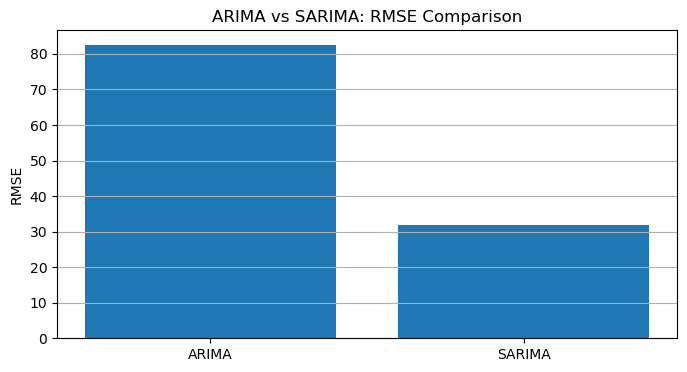

In [33]:
model_comparison = pd.DataFrame({
    "Model": ["ARIMA", "SARIMA"],
    "MAE": [mae, sarima_mae],
    "RMSE": [rmse, sarima_rmse]
})

display(model_comparison)

plt.figure(figsize=(8, 4))
plt.bar(model_comparison["Model"], model_comparison["RMSE"])
plt.title("ARIMA vs SARIMA: RMSE Comparison")
plt.ylabel("RMSE")
plt.grid(axis="y")
plt.show()

In [34]:
seasonal_d_comparison = []

for D_value in [0, 1]:
    try:
        model = SARIMAX(
            sarima_train,
            order=(1, 1, 1),
            seasonal_order=(1, D_value, 1, 12),
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        result = model.fit(disp=False)
        forecast = result.forecast(steps=len(sarima_test))
        forecast.index = sarima_test.index

        seasonal_d_comparison.append({
            "Seasonal Differencing (D)": D_value,
            "AIC": result.aic,
            "MAE": mean_absolute_error(sarima_test, forecast),
            "RMSE": np.sqrt(mean_squared_error(sarima_test, forecast))
        })

    except Exception as e:
        print("Model failed for D =", D_value, ":", e)

display(pd.DataFrame(seasonal_d_comparison))

,Seasonal Differencing (D),AIC,MAE,RMSE
0,0,721.684158,18.697311,22.399179
1,1,657.601346,25.268046,31.787297


CO2 Dataset:
1958-03-01    316.100000
1958-04-01    317.200000
1958-05-01    317.433333
1958-06-01    316.529167
1958-07-01    315.625000
Freq: MS, Name: co2, dtype: float64


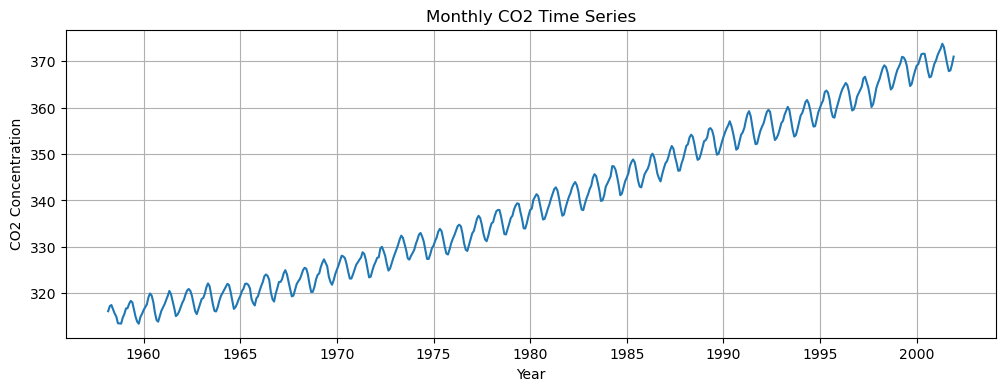

In [35]:
from statsmodels.datasets import co2

# Load CO2 dataset
co2_data = co2.load_pandas().data

# Convert weekly data to monthly averages
co2_series = co2_data["co2"].resample("MS").mean()

# Fill missing monthly values
co2_series = co2_series.interpolate()

print("CO2 Dataset:")
print(co2_series.head())

# Plot original CO2 series
plt.figure(figsize=(12, 4))
plt.plot(co2_series)
plt.title("Monthly CO2 Time Series")
plt.xlabel("Year")
plt.ylabel("CO2 Concentration")
plt.grid()
plt.show()

                                     SARIMAX Results                                      
Dep. Variable:                                co2   No. Observations:                  420
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                 -86.007
Date:                            Mon, 02 Nov 2026   AIC                            182.013
Time:                                    10:08:06   BIC                            201.882
Sample:                                03-01-1958   HQIC                           189.887
                                     - 02-01-1993                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2512      0.119      2.120      0.034       0.019       0.483
ma.L1         -0.5973      0.102   

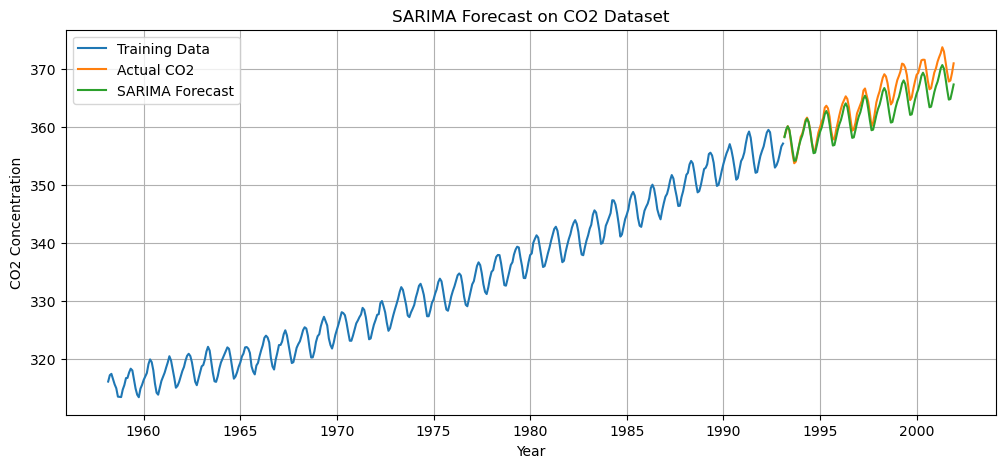

CO2 SARIMA MAE: 1.8527733870893246
CO2 SARIMA RMSE: 2.184325973911014


In [36]:
# Split CO2 dataset
co2_split = int(len(co2_series) * 0.8)

co2_train = co2_series.iloc[:co2_split]
co2_test = co2_series.iloc[co2_split:]

# Fit SARIMA
co2_model = SARIMAX(
    co2_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

co2_result = co2_model.fit(disp=False)

print(co2_result.summary())

# Forecast
co2_forecast = co2_result.forecast(steps=len(co2_test))
co2_forecast.index = co2_test.index

# Plot actual vs forecast
plt.figure(figsize=(12, 5))
plt.plot(co2_train, label="Training Data")
plt.plot(co2_test, label="Actual CO2")
plt.plot(co2_forecast, label="SARIMA Forecast")

plt.title("SARIMA Forecast on CO2 Dataset")
plt.xlabel("Year")
plt.ylabel("CO2 Concentration")
plt.legend()
plt.grid()
plt.show()

# Evaluation
print("CO2 SARIMA MAE:", mean_absolute_error(co2_test, co2_forecast))
print("CO2 SARIMA RMSE:", np.sqrt(mean_squared_error(co2_test, co2_forecast)))